# A short introduction to parallel computing with MPI

<div class="alert alert-block alert-info">
Understanding this notebook is not required for using Heat.
This is a peak under the hood that aims to help understand how Heat works.
</div>

## Contents of this notebook:
- Brief introduction to parallel computing
- Brief introduction to the Message Passing Interface MPI
- MPI example: distributed maximum computation

## Parallel computing
The best illustration of parallel computing is the painting [Weather Forecasting Factory](https://www.emetsoc.org/resources/rff/) by Stephen Conlin about how Lewis Fry Richardson has envisioned numerical weather prediction in the early 20th century.
(Actually, modern numerical weather prediction is so remarkably close to his vision that the UK Met Office name their next production code [LFRic](https://www.metoffice.gov.uk/research/approach/modelling-systems/lfric) after him.)
At the time, computer was a job rather than a machine.
This was a problem because numerical weather prediction requires a great deal of calculations and the weather happens faster than a single human can compute.

So, how to speed up computation in order to reach the required real-time prediction speed?
Wait for the next generation of human to do computations faster?
As this was not an option, the alternative that Richardson came up with was to increase compute power by employing more people.
Assuming we have a set number $A$ of arithmetic operations to perform, if we distribute them among $N$ computers, every computer only needs to perform $A/N$ operations and we hope to get the ideal speedup of $$S_\text{ideal}(N) = \frac{\text{total work}}{\text{work on single computer}} = \frac{A}{A / N} = N.$$

Problem solved?
Not entirely: If Alice predicts the weather in Jülich and Bob predicts the weather in Cologne over the next hour, the two of them need to communicate the results before continuing because their results influence each other.
For non-trivial problems, we need to add in the time it takes to communicate $t_\text{comm}$, and the actually obtained speedup is reduced to $$S(N) = \frac{A}{A/N + t_\text{comm}(N)} < N.$$
In general, the more computers we employ, the fewer computations every individual computer needs to perform, but the time spent communicating does not reduce and eventually we do not gain any more speedup when using more computers.
Furthermore, there are problems that are inherently sequential and require entirely different algorithms to be accelerated by parallel computing.
Here, it is typical to perform more operations than in the serial case on top of the time spent communicating and the speedup with respect to using only a single processor is very limited.

Nevertheless, we are actually in a similar spot as Richardson 100 years ago: We cannot wait for the next generation hardware in order to speed up our code.
Sure, next years hardware will be marginally faster in serial computation, but the majority of increase in power will stem from an increased number of processors over all.
See [this repository](https://github.com/karlrupp/microprocessor-trend-data) for the famous Moore's law of exponentially growing compute power of integrated circuits over time and today's modified version of exponential growth of compute power of overall machines.
So: Whether we want to or not, we have to develop parallel code if we want to efficiently use current machines.

The point of Heat is to hide all of the intricacies of parallelisation from you and let you just use the machines. Regardless, we will take a short peak under the hood.

<div class="alert alert-block alert-info">
<b>Summary:</b> Parallel computing is tricky, typically requires additional computation and communication, and does not give ideal speedup.
But the hardware we have is massively parallel and our code has to match that.
</div>

## The Message Passing Interface MPI
Heat is based on MPI for parallel implementations.
There are many different ways of implementing parallel code and this is actually how MPI was formed.
MPI is a standard that you can read on the [MPI Forum webpage](https://www.mpi-forum.org/docs/).
In early days of parallel computing every vendor and their aunt developed their own way of implementing parallel code.
This was terrible for portability and people quickly got fed up.
Various groups consolidated and only few ways of parallel coding survive from the day.

One of the more prominent ones is MPI, which remains extremely portable today, due to it being a standard.
Various implementations of the MPI standard exist (OpenMPI, MPICH, IntelMPI, ...) and you will find one that works on your machine.
The implementations all adhere to the standard such that the results are the same, but they can differ in performance because they are free to choose the communication algorithm going on in the back.

For instance, when broadcasting from one task to all other tasks, a simple algorithm would be to send from the root task to every other task one after another.
A more performant algorithm would be a tree algorithm where the root task sends to two other tasks, which then each send to two other tasks, and so on, until every task has received the data.
The latter algorithm would give much better performance if the communication is latency bound, but not so much when it is bandwidth bound.
Regardless of performance details, the portability afforded by MPI allows to develop code on your laptop and then run on your local HPC machines or wherever you want.

### The central philosophy of MPI
The central philosophy of MPI is that you launch multiple tasks and give each task the same code to execute.
The tasks are grouped into communicators and can be uniquely addressed within the communicator by a number called rank.
<div class="alert alert-block alert-info">
Since all tasks process the same code, the only way to make them do different things is by addressing them via their <b>rank</b> attribute of the <b>MPI communicator</b>.
</div>

Let's do a little hello world example.
We write the code to a file rather than just execute it in the cell directly.
We do this so we can run the resulting script with any number of tasks, which you will see just below the next code cell.

In [ ]:
fx = open('MPI_tutorial_hello_world.py', 'w')
h = fx.write('''
from mpi4py import MPI
comm = MPI.COMM_WORLD  # this "world" communicator encompasses all tasks
print(f'Hello from rank {comm.rank} out of {comm.size}')  # print rank and size of the communicator
''')
fx.close()

We now prepend `mpirun -np N` to our usual python command in order to launch with `N` tasks:

In [ ]:
!mpirun -np 4 python MPI_tutorial_hello_world.py

Hello from rank 0 out of 4
Hello from rank 2 out of 4
Hello from rank 3 out of 4
Hello from rank 1 out of 4


You can see that each task executes the print statement and the only difference is in the rank that is assigned to each task.
<div class="alert alert-block alert-info">
The tasks execute the code independently and in no particular order with respect to one another.
Try rerunning the above cell; the output should now appear in a different order.
</div>

### Useful MPI functions
The MPI standard is a hefty document, but most of the time, you get by with a few simple functions.

#### Point-to-point communication
You can exchange data between two tasks by using pairs of MPI send and MPI recv

In [ ]:
fx = open('MPI_tutorial_ptp.py', 'w')
h = fx.write('''
from mpi4py import MPI
comm = MPI.COMM_WORLD  # this "world" communicator encompasses all tasks

if comm.rank == 0:
    comm.send('Hello', dest=1)
if comm.rank == 1:
    received = comm.recv(source=0)
    print(f'Rank {comm.rank} received {received} from 0')
''')
fx.close()

In [ ]:
!mpirun -np 4 python MPI_tutorial_ptp.py

Rank 1 received Hello from 0


`send` and `recv` are blocking: The task will not progress until the data is exchanged.
<div class="alert alert-block alert-info">
If you forget to match `send` with `recv`, the code will deadlock and get stuck without telling you what happened.
Deadlocks can sometimes be very difficult to debug.
</div>
Most MPI functions have a non-blocking version starting with `i`, i.e. `isend` and `irecv` where the code can progress past the communication but the result is only well-defined after a matching wait call.

#### Collective communication
The most common collectives are
- `bcast`: Broadcast data from one task to all others
- `gather`: Gather data from all tasks on one task
- `allgather`: Gather data from all tasks on all tasks
- `alltoall`: Exchange data between all tasks
- `reduce`: Compute a single result from data on all tasks on a single task (e.g. maximum, sum, ...)
- `allreduce`: Compute a single result from all data on all tasks

Don't worry about understanding all details now.
Have a look at the [mpi4py tutorials](https://mpi4py.readthedocs.io/en/stable/tutorial.html) for more information on how to actually implement this in Python if needed (definitely not now).

#### Case sensitivity in mpi4py
If you are using mpi4py, i.e. MPI with Python in particular, watch out for differences in case in the function names.
Lowercase functions (`send`, `bcast`, ...) accept as communication buffers anything that can be [pickled](https://docs.python.org/3/library/pickle.html), and, in fact, will be pickled and unpickled during communication.
This is convenient but impairs performance.
For better performance, use uppercase functions (`Send`, `Bcast`, ...), which require special buffers such as Numpy arrays or Torch tensors, but are be communicated non-serialized.

### Implementing parallel maximum with MPI
As a simple example, we will now implement a fully parallel algorithm for finding the maximum in an array and record the parallel scaling capabilities.

We start with the serial implementation and timing infrastructure

In [ ]:
fx = open('MPI_tutorial_maximum.py', 'w')
h = fx.write('''
import json
import time
import numpy as np
from mpi4py import MPI

N_data = int(1e7)
filename = "MPI_tutorial_maximum_timings.json"
comm = MPI.COMM_WORLD

# define data
np.random.seed(7)
data = np.random.random(N_data)
data = comm.bcast(
    data, root=0
)  # broadcast the random data from one rank to make sure its the same on all ranks


def write_timings(comm, value, elapsed):
    if comm.rank == 0:  # only do IO on rank 0
        # load any previous timings
        try:
            with open(filename) as f:
                timings = json.load(f)
        except FileNotFoundError:
            timings = {}

        timings[str(comm.size)] = elapsed

        # write new timings
        with open(filename, "w") as f:
            json.dump(
                timings,
                f,
                indent=2,
            )

        print(
            f"Found maximum {value:.9f} in {elapsed:.6f} seconds with {comm.size} tasks"
        )


if comm.size == 1:
    start = time.perf_counter()
    maximum = max(data)
    elapsed = time.perf_counter() - start
    write_timings(comm, maximum, elapsed)
''')
fx.close()

In [ ]:
!python MPI_tutorial_maximum.py

Found maximum 0.999999828 in 0.307050 seconds with 1 tasks


The simplest way to parallelize this is a two step algorithm: First, distribute the data among tasks and compute the local maximum.
Second, communicate local maxima and compute global maximum as maximum of local maxima.
We use the function `allgather` to communicate.
Here, all tasks receive the same data which is a list of the data gathered from all tasks.

In [ ]:
fx = open('MPI_tutorial_maximum.py', 'a')
h = fx.write('''
if comm.size > 1:
    rank, size = comm.rank, comm.size

    start = time.perf_counter()

    # define local data
    local_size = int(N_data / size)
    if comm.rank == comm.size - 1:
        local_data = data[rank * local_size :]
    else:
        local_data = data[rank * local_size : (rank + 1) * local_size]

    # compute local maximum
    local_maximum = max(local_data)

    # communicate
    maximum = comm.allreduce(local_maximum, MPI.MAX)

    elapsed = time.perf_counter() - start
    write_timings(comm, maximum, elapsed)
''')
fx.close()

In [ ]:
!mpirun -np 2 python MPI_tutorial_maximum.py
!mpirun -np 4 python MPI_tutorial_maximum.py

Found maximum 0.999999828 in 0.198176 seconds with 2 tasks


Found maximum 0.999999828 in 0.223157 seconds with 4 tasks


<div class="alert alert-block alert-info">
Here, we get only a single line of output per run of the script because we only do IO on rank 0.
</div>
We can see that we found the same result on all tasks, which is good.
Hopefully, you also observe some speedup on your machine.
Let's plot the speedup and see what we got:

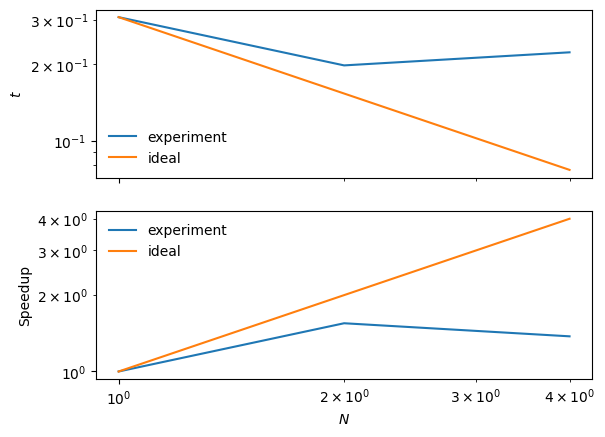

In [ ]:
import matplotlib.pyplot as plt
import json
import numpy as np

with open("MPI_tutorial_maximum_timings.json") as f:
    timings = json.load(f)

N = np.array([int(me) for me in timings.keys()])
t = np.array(list(timings.values()))

fig, axs = plt.subplots(2, 1, sharex=True)

axs[0].loglog(N, t, label='experiment')
axs[1].loglog(N, t[0]/t, label='experiment')

t_ideal = t[0] / (N / N[0])
axs[0].loglog(N, t_ideal, label='ideal')
axs[1].loglog(N, t_ideal[0]/t_ideal, label='ideal')

axs[0].set_ylabel('$t$')
axs[1].set_ylabel('Speedup')
axs[1].set_xlabel('$N$')
axs[0].legend(frameon=False)
axs[1].legend(frameon=False)

On the machine this tutorial was prepared, speedup is close to ideal on two tasks, but no more speedup can be gained when moving to four tasks.
If you get good speedup on four tasks, run the script with 8, 16, 32, ... tasks until you see the speedup saturating.
<div class="alert alert-block alert-info">
The speedup you will observe always depends on your specific machine: processors, memory bandwidth, interconnect, checking for email, ...
</div>
The problem why we don't observe further speedup at some point is the serial step of computing the maximum of all local maxima and the communication cost.
Can you think of an algorithm that could scale further by reducing the serial part?

## Using Heat to avoid all this headache
This is already enough about MPI for now.
You should now know the basics:
1. Launch multiple tasks,
1. give the same code to all tasks,
1. orchestrate using MPI communicators.

Parallel computing is cool.
If you enjoyed this, feel free to dive deeper.
If not, just use Heat instead.
Of course, you can do both and contribute to Heat, which we always welcome!

Here is how to compute the maximum fully parallel in Heat:

In [ ]:
import heat as ht
N_data = int(1e7)
data = ht.random.random(N_data, split=0)
maximum = ht.max(data)

When executing this code snippet in with multiple tasks, Heat will automatically distribute the data among processes along the `split` axis and compute the operation in parallel.
Note that we will not compare performance here because the above example is using Python `max` instead of Numpy `np.max` such that the computation takes sufficiently long to exhibit any parallel speedup here.
For a simple task like computing the maximum of a few numbers, using a compiled library like Numpy is a lot more important than parallelization.
But, as data analysis becomes more elaborate, you need both, which Heat will deliver.
Heat implements many operations like matrix decompositions that are non-trivial to parallelize and require elaborate algorithms and careful implementation.
See [this paper](https://www.eceasst.org/index.php/eceasst/article/view/2626) by Fabian Hoppe for demonstrations of speedup obtained with Heat in practice.

You should now have an idea of what Heat does for you and how it is implemented internally.
Once again, there is no need to remember everything.
Once you have set up MPI and learned how to launch code with multiple tasks, you don't need to think about MPI any more if you just want to use Heat.